# Personalizovana vratanca za Veljka-Debeljka - bez *transfer learning*-a

Ovo je samo demonstracija kakve bi bile  performanse bez transfera znanja. Imajte na umu da možete da poboljšate ove performanse igrajući se sa arhitekturom modela. Međutim, ipak ćete dosta teško dostići performanse pretreniranog modela.

## Kreiranje modela 
Ovo je isti model koji smo koristili za ASL skup podataka. Jedina razlike su: 
* `input_shape` - sada koristimo slike koje su 224 x 224 i u boji (3 kanala).
* na izlaznom sloju imamo 1 neuron i koristimo *binary crossentropy*

In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Conv2D,
    MaxPool2D,
    Flatten,
    Dropout,
    BatchNormalization,
)

model = Sequential()

model.add(Conv2D(75, (3, 3), strides=1, padding="same", activation="relu", 
                 input_shape=(224, 224, 3)))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))

model.add(Conv2D(50, (3, 3), strides=1, padding="same", activation="relu"))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))

model.add(Conv2D(25, (3, 3), strides=1, padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))

model.add(Flatten())
model.add(Dense(units=512, activation="relu"))
model.add(Dropout(0.3))

model.add(Dense(units=1, activation="sigmoid"))

In [2]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 224, 224, 75)      2100      
                                                                 
 batch_normalization (BatchN  (None, 224, 224, 75)     300       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 75)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 50)      33800     
                                                                 
 dropout (Dropout)           (None, 112, 112, 50)      0         
                                                                 
 batch_normalization_1 (Batc  (None, 112, 112, 50)     2

In [3]:
from tensorflow import keras
model.compile(loss=keras.losses.BinaryCrossentropy(from_logits=True), metrics=[keras.metrics.BinaryAccuracy()])

## Učitavanje i augmentacija podataka

In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create a data generator
datagen_train = ImageDataGenerator(
    samplewise_center=True,  # set each sample mean to 0
    rotation_range=10,  # randomly rotate images in the range (degrees, 0 to 180)
    zoom_range=0.1,  # Randomly zoom image
    width_shift_range=0.1,  # randomly shift images horizontally (fraction of total width)
    height_shift_range=0.1,  # randomly shift images vertically (fraction of total height)
    horizontal_flip=True,  # randomly flip images
    vertical_flip=False,
)  # we don't expect Veljko to be upside-down so we will not flip vertically

# No need to augment validation data
datagen_valid = ImageDataGenerator(samplewise_center=True)

In [5]:
# load and iterate training dataset
train_it = datagen_train.flow_from_directory(
    "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/train/",
    target_size=(224, 224),
    color_mode="rgb",
    class_mode="binary",
    batch_size=8,
)

# load and iterate validation dataset
valid_it = datagen_valid.flow_from_directory(
    "/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/veljko-debeljko/valid/",
    target_size=(224, 224),
    color_mode="rgb",
    class_mode="binary",
    batch_size=8,
)

Found 139 images belonging to 2 classes.
Found 31 images belonging to 2 classes.


In [6]:
history = model.fit(train_it, steps_per_epoch=12, validation_data=valid_it, validation_steps=4, epochs=20)

Epoch 1/20


/usr/local/lib/python3.7/dist-packages/tensorflow/python/util/dispatch.py:1082: UserWarning: "`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a sigmoid or softmax activation and thus does not represent logits. Was this intended?"
  return dispatch_target(*args, **kwargs)


12/12 [==============================] - 6s 208ms/step - loss: 9.2333 - binary_accuracy: 0.7143 - val_loss: 80.2367 - val_binary_accuracy: 0.6452
Epoch 2/20
12/12 [==============================] - 3s 262ms/step - loss: 3.7647 - binary_accuracy: 0.8791 - val_loss: 59.1026 - val_binary_accuracy: 0.6452
Epoch 3/20
12/12 [==============================] - 3s 275ms/step - loss: 2.2764 - binary_accuracy: 0.8681 - val_loss: 52.1288 - val_binary_accuracy: 0.6452
Epoch 4/20
12/12 [==============================] - 2s 157ms/step - loss: 2.4297 - binary_accuracy: 0.8791 - val_loss: 28.7337 - val_binary_accuracy: 0.6452
Epoch 5/20
12/12 [==============================] - 2s 144ms/step - loss: 5.1292 - binary_accuracy: 0.8462 - val_loss: 47.6579 - val_binary_accuracy: 0.6452
Epoch 6/20
12/12 [==============================] - 2s 146ms/step - loss: 2.8501 - binary_accuracy: 0.8462 - val_loss: 51.5445 - val_binary_accuracy: 0.6452
Epoch 7/20
12/12 [==============================] - 2s 150ms/step - l

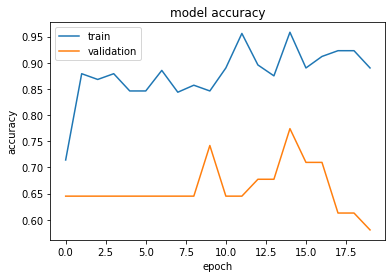

In [7]:
import matplotlib.pyplot as plt
plt.plot(history.history['binary_accuracy'])
plt.plot(history.history['val_binary_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

Tačnost na trening skupu je prilično visoka, međutim, validaciona tačnost je znatno niža. Iz toga vidimo da je model *overfit*-ovan.

Obratite pažnju iznad i na `summary()` modela - u ovoj postavci imamo 10,083,700 podesivih parametara (*trainable parameters*). Kada smo koristili transfer znanja (i zamrzli početne slojeve) i značajno kompleksniji VGG16 model (16 slojeva naspram ovde korišćena 4), imali smo 513 podesivih parametara.